# AHWP w/ klopfenstein

In [62]:
%matplotlib inline

from sympy import *
import sympy as sp
import numpy as np
from math import pi
import matplotlib.pylab as py
import matplotlib.pyplot as plt
from numpy import inf
import cmath
import math
import csv 
import pandas as pd
from decimal import *
import openpyxl
import pprint

#from scipy import optimize,sin,cos



## Def transfer matrix

### Air layer / Isotropic layer

In [63]:
#Layer0(Air)=============================================================================
def Air_layer_0(thetai_deg):
    theta_i = thetai_deg*pi/180.
    
    #epsilon_air--------------------------------------------------------
    ep_xx = 1.
    ep_xy = 0.
    ep_xz = 0.

    ep_yx = 0.
    ep_yy = 1.
    ep_yz = 0.

    ep_zx = 0.
    ep_zy = 0.
    ep_zz = 1.
    
    #q_air------------------------------------------------------------------------------------------
    q_0 = np.sin(theta_i)
    q_01 = np.cos(theta_i)
    q_02 = np.cos(theta_i)
    q_03 = -np.cos(theta_i)
    q_04 = -np.cos(theta_i)

    #gamma_air--------------------------------------------------------------------
    gm_011 = 0.
    gm_012 = np.cos(theta_i)
    gm_013 = -np.sin(theta_i)

    gm_021 = 1.
    gm_022 = 0.
    gm_023 = 0.

    gm_031 = 0.
    gm_032 = np.cos(theta_i)
    gm_033 = np.sin(theta_i)

    gm_041 = 1.
    gm_042 = 0.
    gm_043 = 0.

    #H_0--------------------------------------------------------------------
    H_011 = -1.
    H_012 = 0.
    H_013 = 0.
    
    H_021 = 0.
    H_022 = np.cos(theta_i)
    H_023 = -np.sin(theta_i)

    H_031 = 1.
    H_032 = 0.
    H_033 = 0.

    H_041 = 0.
    H_042 = -np.cos(theta_i)
    H_043 = -np.sin(theta_i)



    #A_i---------------------------------------------------------------------          
    a_011 = gm_011
    a_012 = gm_021
    a_013 = gm_031
    a_014 = gm_041

    a_021 = gm_012
    a_022 = gm_022
    a_023 = gm_032
    a_024 = gm_042

    a_031 = H_011
    a_032 = H_021
    a_033 = H_031
    a_034 = H_041     

    a_041 = H_012
    a_042 = H_022
    a_043 = H_032
    a_044 = H_042 



    #A_0--------------------------------------
    A_0 =np.array([
        [a_011,a_012,a_013,a_014],
        [a_021,a_022,a_023,a_024],
        [a_031,a_032,a_033,a_034],
        [a_041,a_042,a_043,a_044]
    ])


    A_0_inv = np.linalg.inv(A_0)
    
    return A_0, A_0_inv

#FINAL_LAYER==================================================================================================
def Air_layer_f(thetai_deg):
    theta_i = thetai_deg*pi/180.
    #q_fin------------------------------------------------------------------------------------------
    q_0 = np.sin(theta_i)

    q_f1 = np.cos(theta_i)
    q_f2 = np.cos(theta_i)
    q_f3 = 0.
    q_f4 = 0.

    #gamma_fin--------------------------------------------------------------------
    gm_f11 = 0.
    gm_f12 = np.cos(theta_i)
    gm_f13 = -np.sin(theta_i)

    gm_f21 = 1.
    gm_f22 = 0.
    gm_f23 = 0.

    gm_f31 = 0.
    gm_f32 = np.cos(theta_i)
    gm_f33 = np.sin(theta_i)

    gm_f41 = 1.
    gm_f42 = 0.
    gm_f43 = 0.

    #H_fin--------------------------------------------------------------------
    H_f11 = -1.
    H_f12 = 0.
    H_f13 = 0.

    H_f21 = 0.
    H_f22 = np.cos(theta_i)
    H_f23 = -np.sin(theta_i)

    H_f31 = 1.
    H_f32 = 0.
    H_f33 = 0.

    H_f41 = 0.
    H_f42 = -np.cos(theta_i)
    H_f43 = -np.sin(theta_i)

    #A_fin---------------------------------------------------------------------          
    af11 = gm_f11
    af12 = gm_f21
    af13 = gm_f31
    af14 = gm_f41

    af21 = gm_f12
    af22 = gm_f22
    af23 = gm_f32
    af24 = gm_f42

    af31 = H_f11
    af32 = H_f21
    af33 = H_f31
    af34 = H_f41     

    af41 = H_f12
    af42 = H_f22
    af43 = H_f32
    af44 = H_f42 



    #A_fin--------------------------------------
    A_f =np.array([
        [af11,af12,af13,af14],
        [af21,af22,af23,af24],
        [af31,af32,af33,af34],
        [af41,af42,af43,af44]
    ])



    A_f_inv = np.linalg.inv(A_f)
    return A_f, A_f_inv

In [64]:
#Isotroic_Layer===========================================================================================================
def iso_layer(n,thetai_deg,freq_GHz,d): 
    theta_i = thetai_deg*pi/180.
    d=d*(10.**-3.)
    C = 299792458.
    freq = freq_GHz*10.**9.
    k_0 = 2.*np.pi*freq/C
    #epsilon_AR---------------------------------------------------
    ep_xx = n
    ep_xy = 0.
    ep_xz = 0.

    ep_yx = 0.
    ep_yy = n
    ep_yz = 0.

    ep_zx = 0.
    ep_zy = 0.
    ep_zz = n

    theta = np.arcsin(np.sin(theta_i)/n)
    #print(d_AR)
    #q_AR------------------------------------------------------------------------------------------

    q_0 = np.sin(theta_i)

    q_1 = n*np.cos(theta)
    q_2 = n*np.cos(theta)
    q_3 = -n*np.cos(theta)
    q_4 = -n*np.cos(theta)

    #E_AR--------------------------------------------------------------------

    gm_11 = 0.
    gm_12 = np.cos(theta)/n
    gm_13 = -np.sin(theta)/n

    gm_21 = 1./n
    gm_22 = 0.
    gm_23 = 0.

    gm_31 = 0.
    gm_32 = np.cos(theta)/n
    gm_33 = np.sin(theta)/n

    gm_41 = 1./n
    gm_42 = 0.
    gm_43 = 0.

    #H_AR--------------------------------------------------------------------
    H_11 = -1.
    H_12 = 0.
    H_13 = 0.

    H_21 = 0.
    H_22 = np.cos(theta)
    H_23 = -np.sin(theta)

    H_31 = 1.
    H_32 = 0.
    H_33 = 0.

    H_41 = 0.
    H_42 = -np.cos(theta)
    H_43 = -np.sin(theta)



    #A_ARr---------------------------------------------------------------------          
    a_11 = gm_11
    a_12 = gm_21
    a_13 = gm_31
    a_14 = gm_41

    a_21 = gm_12
    a_22 = gm_22
    a_23 = gm_32
    a_24 = gm_42

    a_31 = H_11
    a_32 = H_21
    a_33 = H_31
    a_34 = H_41   

    a_41 = H_12
    a_42 = H_22
    a_43 = H_32
    a_44 = H_42



    #A--------------------------------------
    A =np.array([
        [a_11,a_12,a_13,a_14],
        [a_21,a_22,a_23,a_24],
        [a_31,a_32,a_33,a_34],
        [a_41,a_42,a_43,a_44]
    ])


    A_inv = np.linalg.inv(A)

    #P_AR--------------------------------------------------------------------------------
    p_11 = np.exp(-1j*2.*np.pi*freq*d*q_1/C)    
    p_22 = np.exp(-1j*2.*np.pi*freq*d*q_2/C)   
    p_33 = np.exp(-1j*2.*np.pi*freq*d*q_3/C)   
    p_44 = np.exp(-1j*2.*np.pi*freq*d*q_4/C)           

    P = np.array([
        [p_11,0.,0.,0.],
        [0.,p_22,0.,0.],
        [0.,0.,p_33,0.],
        [0.,0.,0.,p_44]
     ])
    
    T = A.dot(P).dot(A_inv)
    return A, A_inv, P, T

### Rotating birefringent layer

In [75]:

def rot_birefringent_layer(thickness,phi_deg,thetai_deg,rho_deg,freq_GHz,no,ne):
    A = []
    A_inv = []
    P = []
    T = []
    
    theta_i = thetai_deg*pi/180.
    ep_X = no**2.
    ep_Y = ne**2.
    ep_Z = no**2.
    n_X=np.sqrt(ep_X)
    n_Y=np.sqrt(ep_Y)
    n_o = n_X
    theta_2 = np.arcsin(np.sin(theta_i)/n_o)
    d=thickness*(10.**-3.)
    C = 299792458.
    freq = freq_GHz*10.**9.
    k_0 = 2.*np.pi*freq/C
    ep_x = no**2.
    ep_y = ne**2.
    ep_z = no**2.
    
    for i in rho_deg:
        phi =phi_deg*pi/180.
        rho = i*pi/180.

        #誘電率ベクトル--------------------------------------------------------
        ep_xx = ep_X*np.cos(rho)**2. + ep_Y*np.cos(phi)**2.*np.sin(rho)**2. + ep_Z*np.sin(phi)**2.*np.sin(rho)**2.
        ep_xy = (np.sin(2.*rho)/2.)*(ep_X - ep_Y*np.cos(phi)**2. - ep_Z*np.sin(phi)**2.)
        ep_xz = (-ep_Y+ep_Z)*(np.sin(rho)*np.sin(2.*phi)/2.)

        ep_yx = ep_xy
        ep_yy = ep_X*np.sin(rho)**2. + ep_Y*np.cos(phi)**2.*np.cos(rho)**2. + ep_Z*np.sin(phi)**2.*np.cos(rho)**2.
        ep_yz = (ep_Y-ep_Z)*np.cos(rho)*np.sin(2.*phi)/2.

        ep_zx = ep_xz
        ep_zy = ep_yz
        ep_zz = ep_Y*np.sin(phi)**2. + ep_Z*np.cos(phi)**2.


        #誘電率ベクトル
        ep_inv_xx = ((np.cos(rho)**2.+np.sin(phi)**2.*np.sin(rho)**2.)/ep_X)+(np.cos(phi)**2.*np.sin(rho)**2./ep_Y)
        ep_inv_xy = np.cos(phi)**2.*np.sin(rho)*np.cos(rho)*(1./ep_X-1./ep_Y)
        #ep_inv_xz = (ep_Y-ep_Z)*(np.cos(2.*phi-rho)-np.cos(2.*phi+rho))/(4.*ep_Y*ep_Z)
        ep_inv_xz = np.sin(phi)*np.cos(phi)*np.sin(rho)*(1./ep_X-1./ep_Y)
        ep_inv_yx = ep_inv_xy
        ep_inv_yy = ((1.-np.cos(phi)**2.*np.cos(rho)**2.)/ep_X)+(np.cos(phi)**2.*np.cos(rho)**2./ep_Y)
        #ep_inv_yz = (-ep_Y+ep_Z)*(np.sin(2.*phi-rho)+np.sin(2.*phi+rho))/(4.*ep_Y*ep_Z)
        ep_inv_yz = -np.sin(phi)*np.cos(phi)*np.cos(rho)*(1./ep_X-1./ep_Y)
        ep_inv_zx = ep_inv_xz
        ep_inv_zy = ep_inv_yz
        ep_inv_zz = np.sin(phi)**2./ep_Y+np.cos(phi)**2./ep_X


        #屈折率・波数ベクトル----------------------------------------------------------------------------------------
        #TM_t
        

        if i % 360 <= 90:
            n_1 =np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. +  ep_y *np.sin(phi)**2.)**2.))*(ep_x**2.* ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(theta_i)**2. - ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2.* ep_x* ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2.* np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4.* np.sin(theta_i)**2. - 2. *ep_x* ep_y* np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2.* ep_x* (-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x* ep_y - ep_x* ep_y* np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. +  np.cos(phi)**2.* np.cos(rho)**2.* ep_x* np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2.* ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2.* np.sin(theta_i)**2. - ep_y* np.sin(phi)**2.* np.sin(theta_i)**2.))))
        elif 90 < i % 360 <= 270:
            n_1 =np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. +ep_y* np.sin(phi)**2.)**2.))*(ep_x**2.* ep_y - ep_x**2.* ep_y* np.sin(phi)**2. + ep_x* ep_y**2.* np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2.* np.sin(theta_i)**2. - np.cos(phi)**2.* np.cos(rho)**2.* ep_x *ep_y *np.sin(theta_i)**2. - ep_x**2.* np.sin(phi)**2.* np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2.*ep_x**2.* np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. - 2. *np.cos(phi)**2.* np.cos(rho)**2.* ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2.* np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *ep_x* ep_y *np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4.* np.sin(theta_i)**2. + 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2.* ep_x *(-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x* ep_y - ep_x *ep_y *np.sin(phi)**2. + ep_y**2.* np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2.* ep_x *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2. *np.sin(theta_i)**2. - ep_y *np.sin(phi)**2. *np.sin(theta_i)**2.))))
        elif 270 < i% 360  <= 360:
            n_1 =np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. +  ep_y *np.sin(phi)**2.)**2.))*(ep_x**2.* ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(theta_i)**2. - ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2.* ep_x* ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2.* np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4.* np.sin(theta_i)**2. - 2. *ep_x* ep_y* np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2.* ep_x* (-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x* ep_y - ep_x* ep_y* np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. +  np.cos(phi)**2.* np.cos(rho)**2.* ep_x* np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2.* ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2.* np.sin(theta_i)**2. - ep_y* np.sin(phi)**2.* np.sin(theta_i)**2.))))

        theta_1 = np.arcsin(np.sin(theta_i)/n_1)


        #TE_t
        n_2= n_o
        #n_2= np.full(73,n_2)
        theta_2 = np.arcsin(np.sin(theta_i)/n_2)

        #TM_r

        if i % 360 <= 90:
            n_3 = np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. + ep_y *np.sin(phi)**2.)**2.))*(ep_x**2. *ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x* ep_y *np.sin(theta_i)**2. -  ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2.* ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x* ep_y *np.sin(phi)**2.*np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2. *np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *ep_x *ep_y *np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. + 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2. *ep_x *(-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x *ep_y - ep_x *ep_y *np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2. *np.sin(theta_i)**2. - ep_y *np.sin(phi)**2. *np.sin(theta_i)**2.))))
        elif 90 < i % 360 <= 270:
            n_3 = np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. +ep_y *np.sin(phi)**2.)**2.))*(ep_x**2.* ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(theta_i)**2. - ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2. *ep_x* ep_y *np.sin(phi)**2.* np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *ep_x* ep_y* np.sin(phi)**4.* np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2. *ep_x* (-ep_x + ep_y)**2.* np.sin(phi)**2.* np.sin(theta_i)**2. *(ep_x* ep_y - ep_x *ep_y* np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_y *np.sin(theta_i)**2. +ep_x *np.sin(phi)**2.* np.sin(theta_i)**2. - ep_y* np.sin(phi)**2. *np.sin(theta_i)**2.))))
        elif 270 < i  % 360<= 360:
            n_3 = np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. + ep_y *np.sin(phi)**2.)**2.))*(ep_x**2. *ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x* ep_y *np.sin(theta_i)**2. -  ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2.* ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x* ep_y *np.sin(phi)**2.*np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2. *np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *ep_x *ep_y *np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. + 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2. *ep_x *(-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x *ep_y - ep_x *ep_y *np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2. *np.sin(theta_i)**2. - ep_y *np.sin(phi)**2. *np.sin(theta_i)**2.))))

        theta_3 = np.arcsin(np.sin(theta_i)/n_3)

        #TE_r
        n_4 = n_o
        #n_4= np.full(73,n_4)
        theta_4 = np.arcsin(np.sin(theta_i)/n_4)


        #q_ij------------------------------------------------------------------------------------------

        q_0 = np.sin(theta_i)
        
        q_11 = n_1*np.cos(theta_1)
        q_12 = n_2*np.cos(theta_2)
        q_13 = -n_3*np.cos(theta_3)
        q_14 = -n_4*np.cos(theta_4)



        #D_1jk-----------------------------------------------------------------------------------------


        D11_frac=((np.sin(rho)*np.cos(phi)*np.cos(theta_1-theta_2))**2.+((np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2)))**2.+((-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.sin(theta_1))**2.)**(-1./2.)
        D111 = np.sin(rho)*np.cos(phi)*np.cos(theta_1-theta_2)#*D11_frac
        D112 = (np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.cos(theta_1)#*D11_frac
        D113 = (-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.sin(theta_1)#*D11_frac

        D12_frac = ((np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))**2.+(-np.sin(rho)*np.cos(phi)*np.cos(theta_2))**2.+(np.sin(rho)*np.cos(phi)*np.sin(theta_2))**2.)**(-1./2.)
        D121 = (np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))#*D12_frac
        D122 = -np.sin(rho)*np.cos(phi)*np.cos(theta_2)#*D12_frac
        D123 = np.sin(rho)*np.cos(phi)*np.sin(theta_2)#*D12_frac



        D13_frac=((np.sin(rho)*np.cos(phi)*np.cos(theta_3-theta_4))**2.+((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.cos(theta_3))**2.+((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.sin(theta_3))**2.)**(-1./2.)
        D131 = np.sin(rho)*np.cos(phi)*np.cos(theta_3-theta_4)#*D13_frac
        D132 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.cos(theta_3)#*D13_frac
        D133 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.sin(theta_3)#*D13_frac

        D14_frac = ((np.sin(phi)*np.sin(theta_4)+np.cos(phi)*np.cos(rho)*np.cos(theta_4))**2.+(np.sin(rho)*np.cos(phi)*np.cos(theta_4))**2.+(np.sin(rho)*np.cos(phi)*np.sin(theta_4))**2.)**(-1./2.)
        D141 = (np.sin(phi)*np.sin(theta_4)+np.cos(phi)*np.cos(rho)*np.cos(theta_4))#*D14_frac
        D142 = np.sin(rho)*np.cos(phi)*np.cos(theta_4)#*D14_frac
        D143 = np.sin(rho)*np.cos(phi)*np.sin(theta_4)#*D14_frac


        #H_1jk------------------------------------------------------------------------------------------------

        H11_frac=1./np.sqrt((-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))**2.+(np.sin(rho)*np.cos(phi)*np.cos(theta_1)*np.cos(theta_1-theta_2))**2.+(-np.sin(rho)*np.cos(phi)*np.sin(theta_1)*np.cos(theta_1-theta_2))**2.)
        H111 = -np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2)#*H11_frac
        H112 = np.sin(rho)*np.cos(phi)*np.cos(theta_1)*np.cos(theta_1-theta_2)#*H11_frac
        H113 = -np.sin(rho)*np.cos(phi)*np.sin(theta_1)*np.cos(theta_1-theta_2)#*H11_frac

        H12_frac =1./np.sqrt((np.sin(rho)*np.cos(phi))**2.+((np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.cos(theta_2))**2.+((-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.sin(theta_2))**2.)
        H121 =  np.sin(rho)*np.cos(phi)#*H12_frac
        H122 = (np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.cos(theta_2)#*H12_frac
        H123 = (-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.sin(theta_2)#*H12_frac

        H13_frac=1./np.sqrt((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))**2.+(-np.sin(rho)*np.cos(phi)*np.cos(theta_3)*np.cos(theta_3-theta_4))**2.+(-np.sin(rho)*np.cos(phi)*np.sin(theta_3)*np.cos(theta_3-theta_4))**2.)
        H131 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))#*H13_frac
        H132 = -np.sin(rho)*np.cos(phi)*np.cos(theta_3)*np.cos(theta_3-theta_4)#*H13_frac
        H133 = -np.sin(rho)*np.cos(phi)*np.sin(theta_3)*np.cos(theta_3-theta_4)#*H13_frac

        H14_frac=1./np.sqrt((np.sin(rho)*np.cos(phi))**2.+((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.cos(theta_4))**2.+((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.sin(theta_4))**2.)
        H141 = np.sin(rho)*np.cos(phi)#*H14_frac
        H142 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.cos(theta_4)#*H14_frac
        H143 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.sin(theta_4)#*H14_frac

        #gamma_1jk--------------------------------------------------------------------
        gm11_frac=1./np.sqrt((ep_inv_xx*D111 + ep_inv_xy*D112 + ep_inv_xz*D113)**2.+(ep_inv_yx*D111 + ep_inv_yy*D112 + ep_inv_yz*D113)**2.+(ep_inv_zx*D111 + ep_inv_zy*D112 + ep_inv_zz*D113)**2.)
        gm_111 =(ep_inv_xx*D111 + ep_inv_xy*D112 + ep_inv_xz*D113)#*gm11_frac
        gm_112 =(ep_inv_yx*D111 + ep_inv_yy*D112 + ep_inv_yz*D113)#*gm11_frac
        gm_113 =(ep_inv_zx*D111 + ep_inv_zy*D112 + ep_inv_zz*D113)#*gm11_frac

        gm12_frac=1./np.sqrt((ep_inv_xx*D121 + ep_inv_xy*D122 + ep_inv_xz*D123)**2.+(ep_inv_yx*D121 + ep_inv_yy*D122 + ep_inv_yz*D123)**2.+(ep_inv_zx*D121 + ep_inv_zy*D122 + ep_inv_zz*D123)**2.)
        gm_121 =(ep_inv_xx*D121 + ep_inv_xy*D122 + ep_inv_xz*D123)#*gm12_frac
        gm_122 =(ep_inv_yx*D121 + ep_inv_yy*D122 + ep_inv_yz*D123)#*gm12_frac
        gm_123 =(ep_inv_zx*D121 + ep_inv_zy*D122 + ep_inv_zz*D123)#*gm12_frac

        gm13_frac=1./np.sqrt((ep_inv_xx*D131 + ep_inv_xy*D132 + ep_inv_xz*D133)**2.+(ep_inv_yx*D131 + ep_inv_yy*D132 + ep_inv_yz*D133)**2.+(ep_inv_zx*D131 + ep_inv_zy*D132 + ep_inv_zz*D133)**2.)
        gm_131 =(ep_inv_xx*D131 + ep_inv_xy*D132 + ep_inv_xz*D133)#*gm13_frac
        gm_132 =(ep_inv_yx*D131 + ep_inv_yy*D132 + ep_inv_yz*D133)#*gm13_frac
        gm_133 =(ep_inv_zx*D131 + ep_inv_zy*D132 + ep_inv_zz*D133)#*gm13_frac

        gm14_frac=1./np.sqrt((ep_inv_xx*D141 + ep_inv_xy*D142 + ep_inv_xz*D143)**2.+(ep_inv_yx*D141 + ep_inv_yy*D142 + ep_inv_yz*D143)**2.+(ep_inv_zx*D141 + ep_inv_zy*D142 + ep_inv_zz*D143)**2.)
        gm_141 =(ep_inv_xx*D141 + ep_inv_xy*D142 + ep_inv_xz*D143)#*gm14_frac
        gm_142 =(ep_inv_yx*D141 + ep_inv_yy*D142 + ep_inv_yz*D143)#*gm14_frac
        gm_143 =(ep_inv_zx*D141 + ep_inv_zy*D142 + ep_inv_zz*D143)#*gm14_frac

        #A_i=1---------------------------------------------------------------------          
        a111 = gm_111
        a112 = gm_121
        a113 = gm_131
        a114 = gm_141

        a121 = gm_112
        a122 = gm_122
        a123 = gm_132
        a124 = gm_142


        a131 = H111/n_1
        a132 = H121/n_2
        a133 = H131/n_3
        a134 = H141/n_4    

        a141 = H112/n_1
        a142 = H122/n_2
        a143 = H132/n_3
        a144 = H142/n_4  



        #A_1--------------------------------------
        A_mat =np.array([
            [a111,a112,a113,a114],
            [a121,a122,a123,a124],
            [a131,a132,a133,a134],
            [a141,a142,a143,a144]
        ])

        A_mat_inv = np.linalg.inv(A_mat)
        
        if (freq_GHz == 60.) and (i == 0):  # 例：最初のrhoだけ
            print("n1..n4", n_1, n_2, n_3, n_4)
            print("q11..q14", q_11, q_12, q_13, q_14)
            print("A_mat", A_mat)

        #P_i--------------------------------------------------------------------------------
        p_11 = np.exp(-1j*2.*np.pi*freq*d*q_11/C)    
        p_22 = np.exp(-1j*2.*np.pi*freq*d*q_12/C)   
        p_33 = np.exp(-1j*2.*np.pi*freq*d*q_13/C)   
        p_44 = np.exp(-1j*2.*np.pi*freq*d*q_14/C)           

        P_mat =np.array([
            [p_11,0.,0.,0.],
            [0.,p_22,0.,0.],
            [0.,0.,p_33,0.],
            [0.,0.,0.,p_44]
        ])
        
        A.append(A_mat)
        A_inv.append(A_mat_inv)
        P.append(P_mat)
        T.append(A_mat.dot(P_mat).dot(A_mat_inv))
    return  A, A_inv, P, T


## Jones to Mueller matrix

In [76]:
im=complex(0.,1.)
def Jones_to_Mueller(j11,j22,j12,j21):
    m = np.zeros((4,4),'complex')
    m[0][0]=0.5*(j11*np.conjugate(j11)+j21*np.conjugate(j21)+j12*np.conjugate(j12)+j22*np.conjugate(j22))
    m[0][1]=-0.5*(j22*np.conjugate(j22)-j21*np.conjugate(j21)+j12*np.conjugate(j12)-j11*np.conjugate(j11))
    m[0][2]=0.5*(j21*np.conjugate(j22)+j22*np.conjugate(j21)+j11*np.conjugate(j12)+j12*np.conjugate(j11))
    m[0][3]=-0.5*im*(j21*np.conjugate(j22)-j22*np.conjugate(j21)+j11*np.conjugate(j12)-j11*np.conjugate(j12))

    m[1][0]=-0.5*(j22*np.conjugate(j22)+j21*np.conjugate(j21)-j12*np.conjugate(j12)-j11*np.conjugate(j11))
    m[1][1]=0.5*(j22*np.conjugate(j22)-j21*np.conjugate(j21)-j12*np.conjugate(j12)+j11*np.conjugate(j11))
    m[1][2]=-0.5*(j21*np.conjugate(j22)+j22*np.conjugate(j21)-j11*np.conjugate(j12)-j12*np.conjugate(j11))
    m[1][3]=0.5*im*(j21*np.conjugate(j22)-j22*np.conjugate(j21)-j11*np.conjugate(j12)+j21*np.conjugate(j11))

    m[2][0]=0.5*(j12*np.conjugate(j22)+j22*np.conjugate(j12)+j11*np.conjugate(j21)+j21*np.conjugate(j11))
    m[2][1]=-0.5*(j12*np.conjugate(j22)+j22*np.conjugate(j12)-j11*np.conjugate(j21)-j21*np.conjugate(j11))
    m[2][2]=0.5*(j11*np.conjugate(j22)+j22*np.conjugate(j11)+j12*np.conjugate(j21)+j21*np.conjugate(j12))
    m[2][3]=-0.5*im*(j11*np.conjugate(j22)-j22*np.conjugate(j11)-j12*np.conjugate(j21)+j21*np.conjugate(j12))

    m[3][0]=0.5*im*(j12*np.conjugate(j22)-j22*np.conjugate(j12)+j11*np.conjugate(j21)-j21*np.conjugate(j11))
    m[3][1]=-0.5*im*(j12*np.conjugate(j22)-j22*np.conjugate(j12)-j11*np.conjugate(j21)+j21*np.conjugate(j11))
    m[3][2]=0.5*im*(j11*np.conjugate(j22)-j22*np.conjugate(j11)+j12*np.conjugate(j21)-j21*np.conjugate(j12))
    m[3][3]=0.5*(j11*np.conjugate(j22)+j22*np.conjugate(j11)-j12*np.conjugate(j21)-j21*np.conjugate(j12))

    return m


## Def Klopfenstein layer

Gamma =  0.03878242227997966 A =  3.45


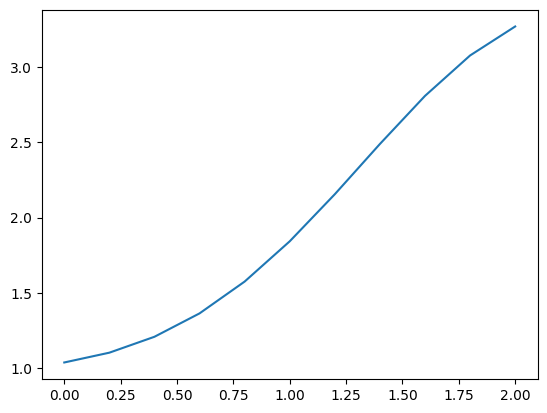

[1.03954428 1.10453914 1.21001838 1.36505526 1.57605745 1.84309522
 2.15537829 2.48854394 2.80739537 3.07549082 3.26777808]
[0.  0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2. ]
[1.07204171 1.15727876 1.28753682 1.47055635 1.70957633 1.99923676
 2.32196112 2.64796965 2.94144309 3.17163445]
[0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2]


In [77]:
#いただいた計算コードそのままと思われます。


import numpy as np
import matplotlib.pyplot as plt
import scipy.special as special
import scipy.integrate as integrate


def Klopfenstein(h,num,ni,ns,A):
    
    z_arr = np.linspace(0,h,num)
    z_space = np.ones(len(z_arr))*(h/num)
    n_arr = np.zeros(num)
    
    rho_0 = 0.5*np.log(ns/ni)
    Gamma = rho_0/np.cosh(A)
    
    print('Gamma = ',Gamma, 'A = ', A)
    
    for i in range(0,num):
        x_i = 2.*z_arr[i]/h-1.
        phi_int = integrate.quad(lambda y: special.i1(A*np.sqrt(1.-y**2))/(A*np.sqrt(1.-y**2)), 0, x_i)
        n_arr[i] = np.sqrt(ni*ns) * np.exp(Gamma * A**2 * phi_int[0])
    return n_arr,z_arr, z_space
    
    
    
h = 2.000 # Height [mm]
num = 11
ni = 1. # index air
ns = 3.397 # index substrate
A = 3.45 # To calculate Gammma

n, z, d = Klopfenstein(h,num,ni,ns,A)
#n: index
#z: height [z]
#d: thickness each layer [mm]

plt.plot(z,n)
plt.show()

print(n)
print(z)

nAR = []
dAR = []
for i in range(len(n)-1):
    n_ave = (n[i]+n[i+1])/2.
    d = z[i+1]-z[i]
    nAR = np.append(nAR, n_ave)
    dAR = np.append(dAR, d)

print(nAR)
print(dAR)

## Def Modulated signal /freq

In [78]:

#======================== 各値の定義 ==============================
thetai_deg = 10. #incident angle[deg.] 

n_AR = np.array(nAR)       #AR index
dAR = 2./10.   #AR thickness[mm] (2mmのARを10分割)

no = 3.059 - 1j*0.000137655    #HWP index
ne = 3.397 - 1j*0.00023779     #HWP index
dHWP1 = 5.000   #HWP thickness[mm]
dHWP2 = 5.000 
dHWP3 = 5.000 
dHWP4 = 5.000 
dHWP5 = 5.000 
phi_deg = 0.    #Off-axis angle[deg.]
rho_deg = np.arange(0.,361.,1.)
#=================================================================


#layer(0) = air
A_0,A_0_inv = Air_layer_0(thetai_deg)
#layer(N+1) = air
A_f,A_f_inv = Air_layer_f(thetai_deg)
#print(A_0)
freq_GHz_arr = np.arange(60.,151.,30.) 
freq_GHz = freq_GHz_arr[0]

print(nAR[0], dAR)

A_AR1,A_AR1_inv,P_AR1,T_AR1 = iso_layer(nAR[0],thetai_deg,freq_GHz,dAR)

print(P_AR1)
print(T_AR1)

1.0720417107404043 0.2
[[0.96481448-0.26293159j 0.        +0.j         0.        +0.j
  0.        +0.j        ]
 [0.        +0.j         0.96481448-0.26293159j 0.        +0.j
  0.        +0.j        ]
 [0.        +0.j         0.        +0.j         0.96481448+0.26293159j
  0.        +0.j        ]
 [0.        +0.j         0.        +0.j         0.        +0.j
  0.96481448+0.26293159j]]
[[9.64814479e-01+0.00000000e+00j 0.00000000e+00+0.00000000e+00j
  0.00000000e+00+0.00000000e+00j 1.11022302e-16-2.48544689e-01j]
 [0.00000000e+00+0.00000000e+00j 9.64814479e-01+0.00000000e+00j
  0.00000000e+00+2.42023578e-01j 0.00000000e+00+0.00000000e+00j]
 [0.00000000e+00+0.00000000e+00j 0.00000000e+00+2.85645807e-01j
  9.64814479e-01+0.00000000e+00j 0.00000000e+00+0.00000000e+00j]
 [0.00000000e+00-2.78151268e-01j 0.00000000e+00+0.00000000e+00j
  0.00000000e+00+0.00000000e+00j 9.64814479e-01-2.77555756e-17j]]


In [79]:

#======================== 各値の定義 ==============================
thetai_deg = 10. #incident angle[deg.] 

n_AR = np.array(nAR)       #AR index
dAR = 2./10.   #AR thickness[mm] (2mmのARを10分割)

no = 3.059 - 1j*0.000137655    #HWP index
ne = 3.397 - 1j*0.00023779     #HWP index
dHWP1 = 5.000   #HWP thickness[mm]
dHWP2 = 5.000 
dHWP3 = 5.000 
dHWP4 = 5.000 
dHWP5 = 5.000 
phi_deg = 10.    #Off-axis angle[deg.]
rho_deg = np.arange(0.,361.,1.)
#=================================================================


#layer(0) = air
A_0,A_0_inv = Air_layer_0(thetai_deg)
#layer(N+1) = air
A_f,A_f_inv = Air_layer_f(thetai_deg)
#print(A_0)

#特定の周波数に対する変調信号を計算します。
def mod_eff_perfreq(freq_GHz):

    #IsotropicLayer = AR
    A_AR1,A_AR1_inv,P_AR1,T_AR1 = iso_layer(nAR[0],thetai_deg,freq_GHz,dAR)
    A_AR2,A_AR2_inv,P_AR2,T_AR2 = iso_layer(nAR[1],thetai_deg,freq_GHz,dAR)
    A_AR3,A_AR3_inv,P_AR3,T_AR3 = iso_layer(nAR[2],thetai_deg,freq_GHz,dAR)
    A_AR4,A_AR4_inv,P_AR4,T_AR4 = iso_layer(nAR[3],thetai_deg,freq_GHz,dAR)
    A_AR5,A_AR5_inv,P_AR5,T_AR5 = iso_layer(nAR[4],thetai_deg,freq_GHz,dAR)
    A_AR6,A_AR6_inv,P_AR6,T_AR6 = iso_layer(nAR[5],thetai_deg,freq_GHz,dAR)
    A_AR7,A_AR7_inv,P_AR7,T_AR7 = iso_layer(nAR[6],thetai_deg,freq_GHz,dAR)
    A_AR8,A_AR8_inv,P_AR8,T_AR8 = iso_layer(nAR[7],thetai_deg,freq_GHz,dAR)
    A_AR9,A_AR9_inv,P_AR9,T_AR9 = iso_layer(nAR[8],thetai_deg,freq_GHz,dAR)
    A_AR10,A__AR10_inv,P_AR10,T_AR10 = iso_layer(nAR[9],thetai_deg,freq_GHz,dAR)
    #A_AR11,A__AR11_inv,P_AR11,T_AR11 = iso_layer(nAR[10],thetai_deg,freq_GHz,dAR)

    #BirefringentLayer = Rot.HWP
    A_HWP1,A_HWP1_inv,P_HWP1,T_HWP1 = rot_birefringent_layer(dHWP1,phi_deg,thetai_deg,rho_deg+88.65,freq_GHz,no,ne)
    A_HWP2,A_HWP2_inv,P_HWP2,T_HWP2 = rot_birefringent_layer(dHWP2,phi_deg,thetai_deg,rho_deg+61.68,freq_GHz,no,ne)
    A_HWP3,A_HWP3_inv,P_HWP3,T_HWP3 = rot_birefringent_layer(dHWP3,phi_deg,thetai_deg,rho_deg,freq_GHz,no,ne)
    A_HWP4,A_HWP4_inv,P_HWP4,T_HWP4 = rot_birefringent_layer(dHWP4,phi_deg,thetai_deg,rho_deg+61.68,freq_GHz,no,ne)
    A_HWP5,A_HWP5_inv,P_HWP5,T_HWP5 = rot_birefringent_layer(dHWP5,phi_deg,thetai_deg,rho_deg+88.65,freq_GHz,no,ne)
    
    
    Iout_TE = []
    Iout_TM = []
    Mueller = []
    #print(nAR[0])
    for i in range (len(A_HWP1)):
        RM = np.array([
            [1.,0.,0.,0.],
            [0.,0.,1.,0.],
            [0.,1.,0.,0.],
            [0.,0.,0.,1.]
        ])
        RM_inv = np.linalg.pinv(RM)
        GM0 = A_0_inv.dot(T_AR1).dot(T_AR2).dot(T_AR3).dot(T_AR4).dot(T_AR5).dot(T_AR6).dot(T_AR7).dot(T_AR8).dot(T_AR9).dot(T_AR10).dot(T_HWP1[i]).dot(T_HWP2[i]).dot(T_HWP3[i]).dot(T_HWP4[i]).dot(T_HWP5[i]).dot(T_AR10).dot(T_AR9).dot(T_AR8).dot(T_AR7).dot(T_AR6).dot(T_AR5).dot(T_AR4).dot(T_AR3).dot(T_AR2).dot(T_AR1).dot(A_f)
        GM = RM_inv.dot(GM0).dot(RM)


        tpp = GM[3][3]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tss = GM[1][1]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tps = GM[3][1]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tsp = GM[1][3]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])

        m = Jones_to_Mueller(tss,tpp,tsp,tps)
        
        Mueller.append(m)
        
        
        #Ip = np.abs(tpp+tsp)
        Ept = (tpp+tsp)
        Est = (tss+tps)

        Ex2_TE = np.abs(tss)**2.
        Iout_TE.append(Ex2_TE)

        Ex2_TM = np.abs(tpp)**2.
        Iout_TM.append(Ex2_TM)
    
    Mueller = np.array(Mueller)
    
    #Mueller matrix, Iout_TM, Iout_TE　のプロットを出すパートです。
    """
    #Mueller matrix
    fig = plt.figure(figsize=(24,24), dpi=150)
    
    ax1 = fig.add_subplot(4,4,1) 
    ax2 = fig.add_subplot(4,4,2) 
    ax3 = fig.add_subplot(4,4,3) 
    ax4 = fig.add_subplot(4,4,4) 
    ax5 = fig.add_subplot(4,4,5) 
    ax6 = fig.add_subplot(4,4,6) 
    ax7 = fig.add_subplot(4,4,7) 
    ax8 = fig.add_subplot(4,4,8) 
    ax9 = fig.add_subplot(4,4,9) 
    ax10 = fig.add_subplot(4,4,10) 
    ax11 = fig.add_subplot(4,4,11) 
    ax12 = fig.add_subplot(4,4,12) 
    ax13 = fig.add_subplot(4,4,13) 
    ax14 = fig.add_subplot(4,4,14) 
    ax15 = fig.add_subplot(4,4,15) 
    ax16 = fig.add_subplot(4,4,16) 
    
    ax1.grid()
    ax2.grid()
    ax3.grid()
    ax4.grid()
    ax5.grid()
    ax6.grid()
    ax7.grid()
    ax8.grid()
    ax9.grid()
    ax10.grid()
    ax11.grid()
    ax12.grid()
    ax13.grid()
    ax14.grid()
    ax15.grid()
    ax16.grid()
    
    #for i in range (len(Mueller)):
    ax1.plot(rho_deg, Mueller[:,0,0].real)
    ax2.plot(rho_deg, Mueller[:,0,1].real)
    ax3.plot(rho_deg, Mueller[:,0,2].real)
    ax4.plot(rho_deg, Mueller[:,0,3].real)
    ax5.plot(rho_deg, Mueller[:,1,0].real)
    ax6.plot(rho_deg, Mueller[:,1,1].real)
    ax7.plot(rho_deg, Mueller[:,1,2].real)
    ax8.plot(rho_deg, Mueller[:,1,3].real)
    ax9.plot(rho_deg, Mueller[:,2,0].real)
    ax10.plot(rho_deg, Mueller[:,2,1].real)
    ax11.plot(rho_deg, Mueller[:,2,2].real)
    ax12.plot(rho_deg, Mueller[:,2,3].real)
    ax13.plot(rho_deg, Mueller[:,3,0].real)
    ax14.plot(rho_deg, Mueller[:,3,1].real)
    ax15.plot(rho_deg, Mueller[:,3,2].real)
    ax16.plot(rho_deg, Mueller[:,3,3].real)

    #Iout_TE
    py.figure()
    py.title('Iout_TE thetai={} phi={} freq={}'.format(thetai_deg,phi_deg,freq_GHz,no,ne), fontsize =18)
    py.plot(rho_deg,Iout_TE,marker=".",linestyle=":") 
    py.xlabel('Rotation angle [deg]', fontsize =18)
    py.ylabel('Iout', fontsize =18)
    py.grid()
    py.tight_layout() 

    #Iout_TM
    py.figure()
    py.title('Iout_TM thetai={} phi={} freq={}'.format(thetai_deg,phi_deg,freq_GHz,no,ne), fontsize =18)
    py.plot(rho_deg,Iout_TM,marker=".",linestyle=":") 
    py.xlabel('Rotation angle [deg]', fontsize =18)
    py.ylabel('Iout', fontsize =18)
    py.grid()
    py.tight_layout() 
    """
    return Iout_TE, Iout_TM, Mueller
    


In [80]:
 
freq_GHz_arr = np.arange(60.,151.,30.) 

Iout_TE_allfreq=[]
Iout_TM_allfreq=[]
Mueller_allfreq = []

for freq_GHz in freq_GHz_arr:
    Iout_TE, Iout_TM, Mueller = mod_eff_perfreq(freq_GHz)
    #print(Iout_TE)
    
    Iout_TE_allfreq.append(Iout_TE)
    Iout_TM_allfreq.append(Iout_TM)
    Mueller_allfreq .append(Mueller)



n1..n4 (3.377289452148486-0.00023184460291474866j) (3.059-0.000137655j) (3.3910244167674413-0.0002354534346127322j) (3.059-0.000137655j)
q11..q14 (3.372822312860382-0.00023215166982736558j) (3.0540673388866546-0.00013787732825612975j) (-3.3865753949457083+0.00023576275519368177j) (-3.0540673388866546+0.00013787732825612975j)
A_mat [[ 0.        +0.00000000e+00j -0.1040197 -9.29908332e-06j
   0.        +0.00000000e+00j  0.10612654+9.58350702e-06j]
 [-0.08500341-1.16433324e-05j  0.        +0.00000000e+00j
  -0.08637382-1.19771448e-05j  0.        +0.00000000e+00j]
 [ 0.28820816+1.96112560e-05j  0.        +0.00000000e+00j
  -0.2928546 -2.04227863e-05j  0.        +0.00000000e+00j]
 [ 0.        +0.00000000e+00j -0.31768317-1.40580683e-05j
   0.        +0.00000000e+00j -0.32411761-1.46362317e-05j]]


In [81]:

np.savez('hoshino.npz',
         IoutTE = Iout_TE_allfreq,
         IoutTM = Iout_TM_allfreq,
         Mueller_allfreq = Mueller_allfreq)

In [10]:

np.savez('/gpfs/home/cmb/yhoshino/Hcode/lbsyssim/wo_offaxis_freq_60_151_30',
         IoutTE = Iout_TE_allfreq,
         IoutTM = Iout_TM_allfreq,
         Mueller_allfreq = Mueller_allfreq)


FileNotFoundError: [Errno 2] No such file or directory: '/gpfs/home/cmb/yhoshino/Hcode/lbsyssim/wo_offaxis_freq_60_151_30.npz'

In [61]:

#======================== 各値の定義 ==============================
thetai_deg = 10. #incident angle[deg.] 

n_AR = np.array(nAR)       #AR index
dAR = 2./10.   #AR thickness[mm] (2mmのARを10分割)

no = 3.059 - 1j*0.000137655    #HWP index
ne = 3.397 - 1j*0.00023779     #HWP index
dHWP1 = 5.000   #HWP thickness[mm]
dHWP2 = 5.000 
dHWP3 = 5.000 
dHWP4 = 5.000 
dHWP5 = 5.000 
phi_deg = 0.    #Off-axis angle[deg.]
rho_deg = np.arange(0.,361.,15.)
#=================================================================


#layer(0) = air
A_0,A_0_inv = Air_layer_0(thetai_deg)
#layer(N+1) = air
A_f,A_f_inv = Air_layer_f(thetai_deg)
#print(A_0)

#特定の周波数に対する変調信号を計算します。
def mod_eff_single_perfreq(freq_GHz):

    #IsotropicLayer = AR
    #BirefringentLayer = Rot.HWP
    A_HWP1,A_HWP1_inv,P_HWP1,T_HWP1 = rot_birefringent_layer(dHWP1,phi_deg,thetai_deg,rho_deg,freq_GHz,no,ne)    
    
    Iout_TE = []
    Iout_TM = []
    Mueller = []
    #print(nAR[0])
    for i in range (len(A_HWP1)):
        RM = np.array([
            [1.,0.,0.,0.],
            [0.,0.,1.,0.],
            [0.,1.,0.,0.],
            [0.,0.,0.,1.]
        ])
        RM_inv = np.linalg.pinv(RM)
        GM0 = A_0_inv.dot(T_HWP1[i]).dot(A_f)
        GM = RM_inv.dot(GM0).dot(RM)


        tpp = GM[3][3]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tss = GM[1][1]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tps = GM[3][1]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tsp = GM[1][3]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])

        m = Jones_to_Mueller(tss,tpp,tsp,tps)
        
        Mueller.append(m)
        
        
        #Ip = np.abs(tpp+tsp)
        Ept = (tpp+tsp)
        Est = (tss+tps)

        Ex2_TE = np.abs(tss)**2.
        Iout_TE.append(Ex2_TE)

        Ex2_TM = np.abs(tpp)**2.
        Iout_TM.append(Ex2_TM)
    
    Mueller = np.array(Mueller)
    print(A_HWP1)
    return Iout_TE, Iout_TM, Mueller
    
 

freq_GHz_arr = np.arange(60.,151.,30.) 

Iout_TE_allfreq=[]
Iout_TM_allfreq=[]
Mueller_allfreq = []

for freq_GHz in freq_GHz_arr:
    Iout_TE, Iout_TM, Mueller = mod_eff_perfreq(freq_GHz)
    #print(Iout_TE)
    
    Iout_TE_allfreq.append(Iout_TE)
    Iout_TM_allfreq.append(Iout_TM)
    Mueller_allfreq .append(Mueller)

n1..n4 (3.3959648521839383-0.0002375887354008982j) (3.059-0.000137655j) (3.3959648521839383-0.0002375887354008982j) (3.059-0.000137655j)
q11..q14 (3.3915223112651955-0.00023789995189366458j) (3.0540673388866546-0.00013787732825612975j) (-3.3915223112651955+0.00023789995189366458j) (-3.0540673388866546+0.00013787732825612975j)
A_mat [[ 0.        +0.00000000e+00j -0.10669404-9.58694237e-06j
   0.        +0.00000000e+00j  0.10669404+9.58694237e-06j]
 [-0.08640513-1.20683009e-05j  0.        +0.00000000e+00j
  -0.08640513-1.20683009e-05j  0.        +0.00000000e+00j]
 [ 0.29399229+2.05255404e-05j  0.        +0.00000000e+00j
  -0.29399229-2.05255404e-05j  0.        +0.00000000e+00j]
 [ 0.        +0.00000000e+00j -0.3258508 -1.45684779e-05j
   0.        +0.00000000e+00j -0.3258508 -1.45684779e-05j]]


In [59]:
Iout_TE_allfreq = np.asarray(Iout_TE_allfreq).transpose()
Iout_TE_allfreq.shape
TE = Iout_TE_allfreq
TE.shape

(25, 4)

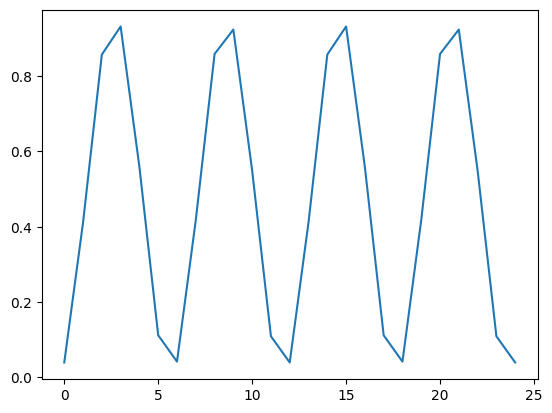

In [60]:
plt.plot(TE[:,0])
plt.show()

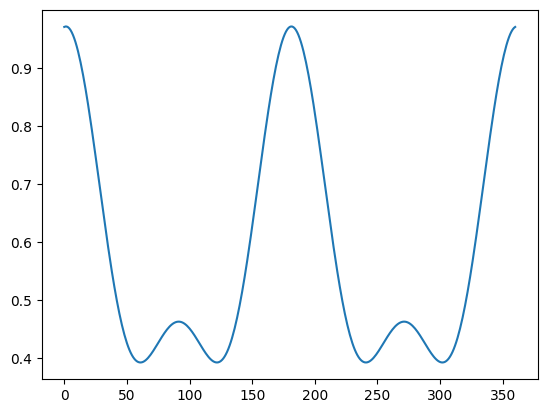

In [13]:
plt.plot(Iout_TE)
plt.show()

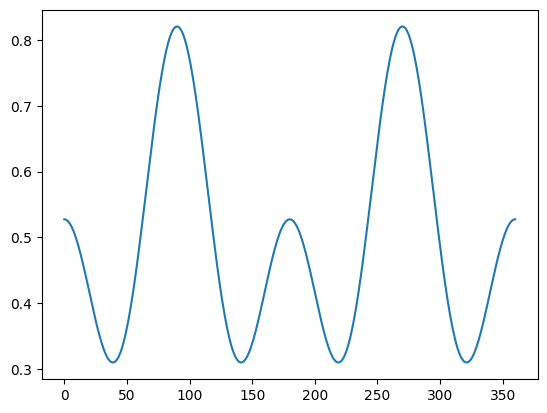

[ 60.  90. 120. 150.]


In [32]:
#Layer0(Air)=============================================================================
def Air_layer_0(thetai_deg):
    theta_i = thetai_deg*pi/180.
    
    #epsilon_air--------------------------------------------------------
    ep_xx = 1.
    ep_xy = 0.
    ep_xz = 0.

    ep_yx = 0.
    ep_yy = 1.
    ep_yz = 0.

    ep_zx = 0.
    ep_zy = 0.
    ep_zz = 1.
    
    #q_air------------------------------------------------------------------------------------------
    q_0 = np.sin(theta_i)
    q_01 = np.cos(theta_i)
    q_02 = np.cos(theta_i)
    q_03 = -np.cos(theta_i)
    q_04 = -np.cos(theta_i)

    #gamma_air--------------------------------------------------------------------
    gm_011 = 0.
    gm_012 = np.cos(theta_i)
    gm_013 = -np.sin(theta_i)

    gm_021 = 1.
    gm_022 = 0.
    gm_023 = 0.

    gm_031 = 0.
    gm_032 = np.cos(theta_i)
    gm_033 = np.sin(theta_i)

    gm_041 = 1.
    gm_042 = 0.
    gm_043 = 0.

    #H_0--------------------------------------------------------------------
    H_011 = -1.
    H_012 = 0.
    H_013 = 0.
    
    H_021 = 0.
    H_022 = np.cos(theta_i)
    H_023 = -np.sin(theta_i)

    H_031 = 1.
    H_032 = 0.
    H_033 = 0.

    H_041 = 0.
    H_042 = -np.cos(theta_i)
    H_043 = -np.sin(theta_i)



    #A_i---------------------------------------------------------------------          
    a_011 = gm_011
    a_012 = gm_021
    a_013 = gm_031
    a_014 = gm_041

    a_021 = gm_012
    a_022 = gm_022
    a_023 = gm_032
    a_024 = gm_042

    a_031 = H_011
    a_032 = H_021
    a_033 = H_031
    a_034 = H_041     

    a_041 = H_012
    a_042 = H_022
    a_043 = H_032
    a_044 = H_042 



    #A_0--------------------------------------
    A_0 =np.array([
        [a_011,a_012,a_013,a_014],
        [a_021,a_022,a_023,a_024],
        [a_031,a_032,a_033,a_034],
        [a_041,a_042,a_043,a_044]
    ])


    A_0_inv = np.linalg.inv(A_0)
    
    return A_0, A_0_inv

#FINAL_LAYER==================================================================================================
def Air_layer_f(thetai_deg):
    theta_i = thetai_deg*pi/180.
    #q_fin------------------------------------------------------------------------------------------
    q_0 = np.sin(theta_i)

    q_f1 = np.cos(theta_i)
    q_f2 = np.cos(theta_i)
    q_f3 = 0.
    q_f4 = 0.

    #gamma_fin--------------------------------------------------------------------
    gm_f11 = 0.
    gm_f12 = np.cos(theta_i)
    gm_f13 = -np.sin(theta_i)

    gm_f21 = 1.
    gm_f22 = 0.
    gm_f23 = 0.

    gm_f31 = 0.
    gm_f32 = np.cos(theta_i)
    gm_f33 = np.sin(theta_i)

    gm_f41 = 1.
    gm_f42 = 0.
    gm_f43 = 0.

    #H_fin--------------------------------------------------------------------
    H_f11 = -1.
    H_f12 = 0.
    H_f13 = 0.

    H_f21 = 0.
    H_f22 = np.cos(theta_i)
    H_f23 = -np.sin(theta_i)

    H_f31 = 1.
    H_f32 = 0.
    H_f33 = 0.

    H_f41 = 0.
    H_f42 = -np.cos(theta_i)
    H_f43 = -np.sin(theta_i)

    #A_fin---------------------------------------------------------------------          
    af11 = gm_f11
    af12 = gm_f21
    af13 = gm_f31
    af14 = gm_f41

    af21 = gm_f12
    af22 = gm_f22
    af23 = gm_f32
    af24 = gm_f42

    af31 = H_f11
    af32 = H_f21
    af33 = H_f31
    af34 = H_f41     

    af41 = H_f12
    af42 = H_f22
    af43 = H_f32
    af44 = H_f42 



    #A_fin--------------------------------------
    A_f =np.array([
        [af11,af12,af13,af14],
        [af21,af22,af23,af24],
        [af31,af32,af33,af34],
        [af41,af42,af43,af44]
    ])



    A_f_inv = np.linalg.inv(A_f)
    return A_f, A_f_inv

def rot_birefringent_layer(thickness,phi_deg,thetai_deg,rho_deg,freq_GHz,no,ne):
    A = []
    A_inv = []
    P = []
    T = []
    
    theta_i = thetai_deg*pi/180.
    ep_X = no**2.
    ep_Y = ne**2.
    ep_Z = no**2.
    n_X=np.sqrt(ep_X)
    n_Y=np.sqrt(ep_Y)
    n_o = n_X
    theta_2 = np.arcsin(np.sin(theta_i)/n_o)
    d=thickness*(10.**-3.)
    C = 299792458.
    freq = freq_GHz*10.**9.
    k_0 = 2.*np.pi*freq/C
    ep_x = no**2.
    ep_y = ne**2.
    ep_z = no**2.
    
    for i in rho_deg:
        phi =phi_deg*pi/180.
        rho = i*pi/180.

        #誘電率ベクトル--------------------------------------------------------
        ep_xx = ep_X*np.cos(rho)**2. + ep_Y*np.cos(phi)**2.*np.sin(rho)**2. + ep_Z*np.sin(phi)**2.*np.sin(rho)**2.
        ep_xy = (np.sin(2.*rho)/2.)*(ep_X - ep_Y*np.cos(phi)**2. - ep_Z*np.sin(phi)**2.)
        ep_xz = (-ep_Y+ep_Z)*(np.sin(rho)*np.sin(2.*phi)/2.)

        ep_yx = ep_xy
        ep_yy = ep_X*np.sin(rho)**2. + ep_Y*np.cos(phi)**2.*np.cos(rho)**2. + ep_Z*np.sin(phi)**2.*np.cos(rho)**2.
        ep_yz = (ep_Y-ep_Z)*np.cos(rho)*np.sin(2.*phi)/2.

        ep_zx = ep_xz
        ep_zy = ep_yz
        ep_zz = ep_Y*np.sin(phi)**2. + ep_Z*np.cos(phi)**2.


        #誘電率ベクトル
        ep_inv_xx = ((np.cos(rho)**2.+np.sin(phi)**2.*np.sin(rho)**2.)/ep_X)+(np.cos(phi)**2.*np.sin(rho)**2./ep_Y)
        ep_inv_xy = np.cos(phi)**2.*np.sin(rho)*np.cos(rho)*(1./ep_X-1./ep_Y)
        #ep_inv_xz = (ep_Y-ep_Z)*(np.cos(2.*phi-rho)-np.cos(2.*phi+rho))/(4.*ep_Y*ep_Z)
        ep_inv_xz = np.sin(phi)*np.cos(phi)*np.sin(rho)*(1./ep_X-1./ep_Y)
        ep_inv_yx = ep_inv_xy
        ep_inv_yy = ((1.-np.cos(phi)**2.*np.cos(rho)**2.)/ep_X)+(np.cos(phi)**2.*np.cos(rho)**2./ep_Y)
        #ep_inv_yz = (-ep_Y+ep_Z)*(np.sin(2.*phi-rho)+np.sin(2.*phi+rho))/(4.*ep_Y*ep_Z)
        ep_inv_yz = np.sin(phi)*np.cos(phi)*np.cos(rho)*(1./ep_X-1./ep_Y)
        ep_inv_zx = ep_inv_xz
        ep_inv_zy = ep_inv_yz
        ep_inv_zz = np.sin(phi)**2./ep_Y+np.cos(phi)**2./ep_X


        #屈折率・波数ベクトル----------------------------------------------------------------------------------------
        #TM_t
        

        if i % 360 <= 90:
            n_1 =np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. +  ep_y *np.sin(phi)**2.)**2.))*(ep_x**2.* ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(theta_i)**2. - ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2.* ep_x* ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2.* np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4.* np.sin(theta_i)**2. - 2. *ep_x* ep_y* np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2.* ep_x* (-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x* ep_y - ep_x* ep_y* np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. +  np.cos(phi)**2.* np.cos(rho)**2.* ep_x* np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2.* ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2.* np.sin(theta_i)**2. - ep_y* np.sin(phi)**2.* np.sin(theta_i)**2.))))
        elif 90 < i % 360 <= 270:
            n_1 =np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. +ep_y* np.sin(phi)**2.)**2.))*(ep_x**2.* ep_y - ep_x**2.* ep_y* np.sin(phi)**2. + ep_x* ep_y**2.* np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2.* np.sin(theta_i)**2. - np.cos(phi)**2.* np.cos(rho)**2.* ep_x *ep_y *np.sin(theta_i)**2. - ep_x**2.* np.sin(phi)**2.* np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2.*ep_x**2.* np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. - 2. *np.cos(phi)**2.* np.cos(rho)**2.* ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2.* np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *ep_x* ep_y *np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4.* np.sin(theta_i)**2. + 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2.* ep_x *(-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x* ep_y - ep_x *ep_y *np.sin(phi)**2. + ep_y**2.* np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2.* ep_x *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2. *np.sin(theta_i)**2. - ep_y *np.sin(phi)**2. *np.sin(theta_i)**2.))))
        elif 270 < i% 360  <= 360:
            n_1 =np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. +  ep_y *np.sin(phi)**2.)**2.))*(ep_x**2.* ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(theta_i)**2. - ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2.* ep_x* ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2.* np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4.* np.sin(theta_i)**2. - 2. *ep_x* ep_y* np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2.* ep_x* (-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x* ep_y - ep_x* ep_y* np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. +  np.cos(phi)**2.* np.cos(rho)**2.* ep_x* np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2.* ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2.* np.sin(theta_i)**2. - ep_y* np.sin(phi)**2.* np.sin(theta_i)**2.))))

        theta_1 = np.arcsin(np.sin(theta_i)/n_1)


        #TE_t
        n_2= n_o
        #n_2= np.full(73,n_2)
        theta_2 = np.arcsin(np.sin(theta_i)/n_2)

        #TM_r

        if i % 360 <= 90:
            n_3 = np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. + ep_y *np.sin(phi)**2.)**2.))*(ep_x**2. *ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x* ep_y *np.sin(theta_i)**2. -  ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2.* ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x* ep_y *np.sin(phi)**2.*np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2. *np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *ep_x *ep_y *np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. + 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2. *ep_x *(-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x *ep_y - ep_x *ep_y *np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2. *np.sin(theta_i)**2. - ep_y *np.sin(phi)**2. *np.sin(theta_i)**2.))))
        elif 90 < i % 360 <= 270:
            n_3 = np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. +ep_y *np.sin(phi)**2.)**2.))*(ep_x**2.* ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(theta_i)**2. - ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2. *ep_x* ep_y *np.sin(phi)**2.* np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *ep_x* ep_y* np.sin(phi)**4.* np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2. *ep_x* (-ep_x + ep_y)**2.* np.sin(phi)**2.* np.sin(theta_i)**2. *(ep_x* ep_y - ep_x *ep_y* np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_y *np.sin(theta_i)**2. +ep_x *np.sin(phi)**2.* np.sin(theta_i)**2. - ep_y* np.sin(phi)**2. *np.sin(theta_i)**2.))))
        elif 270 < i  % 360<= 360:
            n_3 = np.sqrt((1./((ep_x - ep_x *np.sin(phi)**2. + ep_y *np.sin(phi)**2.)**2.))*(ep_x**2. *ep_y - ep_x**2. *ep_y *np.sin(phi)**2. + ep_x *ep_y**2. *np.sin(phi)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x**2. *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_x* ep_y *np.sin(theta_i)**2. -  ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2.* ep_x**2. *np.sin(phi)**2. *np.sin(theta_i)**2. + ep_x* ep_y *np.sin(phi)**2.*np.sin(theta_i)**2. - 2. *np.cos(phi)**2. *np.cos(rho)**2. *ep_x *ep_y *np.sin(phi)**2. *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_y**2. *np.sin(phi)**2.* np.sin(theta_i)**2. + ep_x**2. *np.sin(phi)**4. *np.sin(theta_i)**2. - 2. *ep_x *ep_y *np.sin(phi)**4. *np.sin(theta_i)**2. + ep_y**2. *np.sin(phi)**4. *np.sin(theta_i)**2. + 2. *np.sqrt(np.cos(phi)**2. *np.cos(rho)**2. *ep_x *(-ep_x + ep_y)**2. *np.sin(phi)**2. *np.sin(theta_i)**2. *(ep_x *ep_y - ep_x *ep_y *np.sin(phi)**2. + ep_y**2. *np.sin(phi)**2. - ep_x *np.sin(theta_i)**2. + np.cos(phi)**2. *np.cos(rho)**2. *ep_x *np.sin(theta_i)**2. - np.cos(phi)**2. *np.cos(rho)**2. *ep_y *np.sin(theta_i)**2. + ep_x *np.sin(phi)**2. *np.sin(theta_i)**2. - ep_y *np.sin(phi)**2. *np.sin(theta_i)**2.))))

        theta_3 = np.arcsin(np.sin(theta_i)/n_3)

        #TE_r
        n_4 = n_o
        #n_4= np.full(73,n_4)
        theta_4 = np.arcsin(np.sin(theta_i)/n_4)


        #q_ij------------------------------------------------------------------------------------------

        q_0 = np.sin(theta_i)
        
        q_11 = n_1*np.cos(theta_1)
        q_12 = n_2*np.cos(theta_2)
        q_13 = -n_3*np.cos(theta_3)
        q_14 = -n_4*np.cos(theta_4)


        #D_1jk-----------------------------------------------------------------------------------------


        D11_frac=((np.sin(rho)*np.cos(phi)*np.cos(theta_1-theta_2))**2.+((np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2)))**2.+((-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.sin(theta_1))**2.)**(-1./2.)
        D111 = np.sin(rho)*np.cos(phi)*np.cos(theta_1-theta_2)#*D11_frac
        D112 = (np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.cos(theta_1)#*D11_frac
        D113 = (-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.sin(theta_1)#*D11_frac

        D12_frac = ((np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))**2.+(-np.sin(rho)*np.cos(phi)*np.cos(theta_2))**2.+(np.sin(rho)*np.cos(phi)*np.sin(theta_2))**2.)**(-1./2.)
        D121 = (np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))#*D12_frac
        D122 = -np.sin(rho)*np.cos(phi)*np.cos(theta_2)#*D12_frac
        D123 = np.sin(rho)*np.cos(phi)*np.sin(theta_2)#*D12_frac



        D13_frac=((np.sin(rho)*np.cos(phi)*np.cos(theta_3-theta_4))**2.+((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.cos(theta_3))**2.+((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.sin(theta_3))**2.)**(-1./2.)
        D131 = np.sin(rho)*np.cos(phi)*np.cos(theta_3-theta_4)#*D13_frac
        D132 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.cos(theta_3)#*D13_frac
        D133 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.sin(theta_3)#*D13_frac

        D14_frac = ((np.sin(phi)*np.sin(theta_4)+np.cos(phi)*np.cos(rho)*np.cos(theta_4))**2.+(np.sin(rho)*np.cos(phi)*np.cos(theta_4))**2.+(np.sin(rho)*np.cos(phi)*np.sin(theta_4))**2.)**(-1./2.)
        D141 = (np.sin(phi)*np.sin(theta_4)+np.cos(phi)*np.cos(rho)*np.cos(theta_4))#*D14_frac
        D142 = np.sin(rho)*np.cos(phi)*np.cos(theta_4)#*D14_frac
        D143 = np.sin(rho)*np.cos(phi)*np.sin(theta_4)#*D14_frac


        #H_1jk------------------------------------------------------------------------------------------------

        H11_frac=1./np.sqrt((-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))**2.+(np.sin(rho)*np.cos(phi)*np.cos(theta_1)*np.cos(theta_1-theta_2))**2.+(-np.sin(rho)*np.cos(phi)*np.sin(theta_1)*np.cos(theta_1-theta_2))**2.)
        H111 = -np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2)#*H11_frac
        H112 = np.sin(rho)*np.cos(phi)*np.cos(theta_1)*np.cos(theta_1-theta_2)#*H11_frac
        H113 = -np.sin(rho)*np.cos(phi)*np.sin(theta_1)*np.cos(theta_1-theta_2)#*H11_frac

        H12_frac =1./np.sqrt((np.sin(rho)*np.cos(phi))**2.+((np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.cos(theta_2))**2.+((-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.sin(theta_2))**2.)
        H121 =  np.sin(rho)*np.cos(phi)#*H12_frac
        H122 = (np.sin(phi)*np.sin(theta_2)-np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.cos(theta_2)#*H12_frac
        H123 = (-np.sin(phi)*np.sin(theta_2)+np.cos(phi)*np.cos(rho)*np.cos(theta_2))*np.sin(theta_2)#*H12_frac

        H13_frac=1./np.sqrt((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))**2.+(-np.sin(rho)*np.cos(phi)*np.cos(theta_3)*np.cos(theta_3-theta_4))**2.+(-np.sin(rho)*np.cos(phi)*np.sin(theta_3)*np.cos(theta_3-theta_4))**2.)
        H131 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))#*H13_frac
        H132 = -np.sin(rho)*np.cos(phi)*np.cos(theta_3)*np.cos(theta_3-theta_4)#*H13_frac
        H133 = -np.sin(rho)*np.cos(phi)*np.sin(theta_3)*np.cos(theta_3-theta_4)#*H13_frac

        H14_frac=1./np.sqrt((np.sin(rho)*np.cos(phi))**2.+((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.cos(theta_4))**2.+((-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.sin(theta_4))**2.)
        H141 = np.sin(rho)*np.cos(phi)#*H14_frac
        H142 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.cos(theta_4)#*H14_frac
        H143 = (-np.sin(phi)*np.sin(theta_4)-np.cos(phi)*np.cos(rho)*np.cos(theta_4))*np.sin(theta_4)#*H14_frac

        #gamma_1jk--------------------------------------------------------------------
        gm11_frac=1./np.sqrt((ep_inv_xx*D111 + ep_inv_xy*D112 + ep_inv_xz*D113)**2.+(ep_inv_yx*D111 + ep_inv_yy*D112 + ep_inv_yz*D113)**2.+(ep_inv_zx*D111 + ep_inv_zy*D112 + ep_inv_zz*D113)**2.)
        gm_111 =(ep_inv_xx*D111 + ep_inv_xy*D112 + ep_inv_xz*D113)#*gm11_frac
        gm_112 =(ep_inv_yx*D111 + ep_inv_yy*D112 + ep_inv_yz*D113)#*gm11_frac
        gm_113 =(ep_inv_zx*D111 + ep_inv_zy*D112 + ep_inv_zz*D113)#*gm11_frac

        gm12_frac=1./np.sqrt((ep_inv_xx*D121 + ep_inv_xy*D122 + ep_inv_xz*D123)**2.+(ep_inv_yx*D121 + ep_inv_yy*D122 + ep_inv_yz*D123)**2.+(ep_inv_zx*D121 + ep_inv_zy*D122 + ep_inv_zz*D123)**2.)
        gm_121 =(ep_inv_xx*D121 + ep_inv_xy*D122 + ep_inv_xz*D123)#*gm12_frac
        gm_122 =(ep_inv_yx*D121 + ep_inv_yy*D122 + ep_inv_yz*D123)#*gm12_frac
        gm_123 =(ep_inv_zx*D121 + ep_inv_zy*D122 + ep_inv_zz*D123)#*gm12_frac

        gm13_frac=1./np.sqrt((ep_inv_xx*D131 + ep_inv_xy*D132 + ep_inv_xz*D133)**2.+(ep_inv_yx*D131 + ep_inv_yy*D132 + ep_inv_yz*D133)**2.+(ep_inv_zx*D131 + ep_inv_zy*D132 + ep_inv_zz*D133)**2.)
        gm_131 =(ep_inv_xx*D131 + ep_inv_xy*D132 + ep_inv_xz*D133)#*gm13_frac
        gm_132 =(ep_inv_yx*D131 + ep_inv_yy*D132 + ep_inv_yz*D133)#*gm13_frac
        gm_133 =(ep_inv_zx*D131 + ep_inv_zy*D132 + ep_inv_zz*D133)#*gm13_frac

        gm14_frac=1./np.sqrt((ep_inv_xx*D141 + ep_inv_xy*D142 + ep_inv_xz*D143)**2.+(ep_inv_yx*D141 + ep_inv_yy*D142 + ep_inv_yz*D143)**2.+(ep_inv_zx*D141 + ep_inv_zy*D142 + ep_inv_zz*D143)**2.)
        gm_141 =(ep_inv_xx*D141 + ep_inv_xy*D142 + ep_inv_xz*D143)#*gm14_frac
        gm_142 =(ep_inv_yx*D141 + ep_inv_yy*D142 + ep_inv_yz*D143)#*gm14_frac
        gm_143 =(ep_inv_zx*D141 + ep_inv_zy*D142 + ep_inv_zz*D143)#*gm14_frac

        #A_i=1---------------------------------------------------------------------          
        a111 = gm_111
        a112 = gm_121
        a113 = gm_131
        a114 = gm_141

        a121 = gm_112
        a122 = gm_122
        a123 = gm_132
        a124 = gm_142


        a131 = H111/n_1
        a132 = H121/n_2
        a133 = H131/n_3
        a134 = H141/n_4    

        a141 = H112/n_1
        a142 = H122/n_2
        a143 = H132/n_3
        a144 = H142/n_4  



        #A_1--------------------------------------
        A_mat =np.array([
            [a111,a112,a113,a114],
            [a121,a122,a123,a124],
            [a131,a132,a133,a134],
            [a141,a142,a143,a144]
        ])

        A_mat_inv = np.linalg.inv(A_mat)

        #P_i--------------------------------------------------------------------------------
        p_11 = np.exp(-1j*2.*np.pi*freq*d*q_11/C)    
        p_22 = np.exp(-1j*2.*np.pi*freq*d*q_12/C)   
        p_33 = np.exp(-1j*2.*np.pi*freq*d*q_13/C)   
        p_44 = np.exp(-1j*2.*np.pi*freq*d*q_14/C)           

        P_mat =np.array([
            [p_11,0.,0.,0.],
            [0.,p_22,0.,0.],
            [0.,0.,p_33,0.],
            [0.,0.,0.,p_44]
        ])
        
        A.append(A_mat)
        A_inv.append(A_mat_inv)
        P.append(P_mat)
        T.append(A_mat.dot(P_mat).dot(A_mat_inv))
    return  A, A_inv, P, T



#特定の周波数に対する変調信号を計算します。
def mod_eff_perfreq(freq_GHz):
    #BirefringentLayer = Rot.HWP
    A_HWP1,A_HWP1_inv,P_HWP1,T_HWP1 = rot_birefringent_layer(dHWP1,phi_deg,thetai_deg,rho_deg,freq_GHz,no,ne)    
    
    Iout_TE = []
    Iout_TM = []
    Mueller = []
    #print(nAR[0])
    for i in range (len(A_HWP1)):
        RM = np.array([
            [1.,0.,0.,0.],
            [0.,0.,1.,0.],
            [0.,1.,0.,0.],
            [0.,0.,0.,1.]
        ])
        RM_inv = np.linalg.pinv(RM)
        GM0 = A_0_inv.dot(T_HWP1[i]).dot(A_f)
        GM = RM_inv.dot(GM0).dot(RM)


        tpp = GM[3][3]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tss = GM[1][1]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tps = GM[3][1]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])
        tsp = GM[1][3]/(GM[1][1]*GM[3][3]-GM[1][3]*GM[3][1])

        m = Jones_to_Mueller(tss,tpp,tsp,tps)
        
        Mueller.append(m)
        
        
        #Ip = np.abs(tpp+tsp)
        Ept = (tpp+tsp)
        Est = (tss+tps)

        Ex2_TE = np.abs(tss)**2.
        Iout_TE.append(Ex2_TE)

        Ex2_TM = np.abs(tpp)**2.
        Iout_TM.append(Ex2_TM)
    
    Mueller = np.array(Mueller)
    
    return Iout_TE, Iout_TM, Mueller





#======================== 各値の定義 ==============================
thetai_deg = 10. #incident angle[deg.] 

no = 3.059 - 1j*0.000137655    #HWP index
ne = 3.397 - 1j*0.00023779     #HWP index
dHWP1 = 5.000   #HWP thickness[mm]
phi_deg = 0.    #Off-axis angle[deg.]
rho_deg = np.arange(0.,361.,1.)
#=================================================================


#layer(0) = air
A_0,A_0_inv = Air_layer_0(thetai_deg)
#layer(N+1) = air
A_f,A_f_inv = Air_layer_f(thetai_deg)
#print(A_0)

freq_GHz_arr = np.arange(60.,151.,30.) 

Iout_TE_allfreq=[]
Iout_TM_allfreq=[]
Mueller_allfreq = []

for freq_GHz in freq_GHz_arr:
    Iout_TE, Iout_TM, Mueller = mod_eff_perfreq(freq_GHz)
    
    Iout_TE_allfreq.append(Iout_TE)
    Iout_TM_allfreq.append(Iout_TM)
    Mueller_allfreq .append(Mueller)
    
Iout_TE_allfreq = np.asarray(Iout_TE_allfreq)
Iout_TE_allfreq.shape
    
plt.plot(Iout_TM_allfreq[0])
plt.show()
print(freq_GHz_arr)

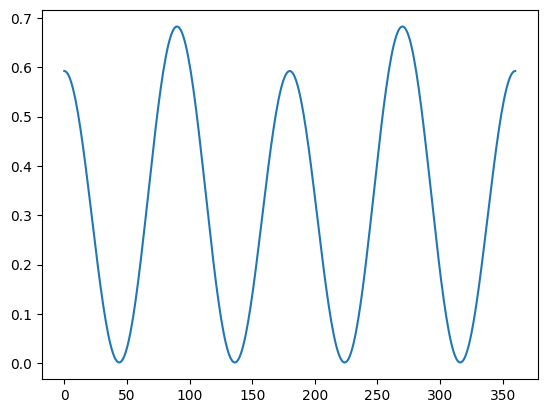

[ 60.  90. 120. 150.]


In [39]:
rho_deg = np.arange(0.,361.,1.)